# Construisons un module de géométrie (2/2)

Continuons le TP précédent pour fabriquer notre module de géométrie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import TP08_geometrie as geom

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## Déplaçons les objets

> 1. Créez une fonction `move` dans les classes `disque` et `polygone` qui prend en argument un vecteur de deux coordonnées et qui déplace l'objet géométrique.
> 2. Créez une fonction `rotate` dans les classes `disque` et `polygone` qui prend en argument un angle et qui fait tourner l'objet géométrique par rapport à son centre de gravité.
> 3. Testez ensuite vos fonctions.

*Indication : pour le cercle, il suffira de déplacer le centre du disque ; pour le polygone, il faut déplacer tous les sommets.*

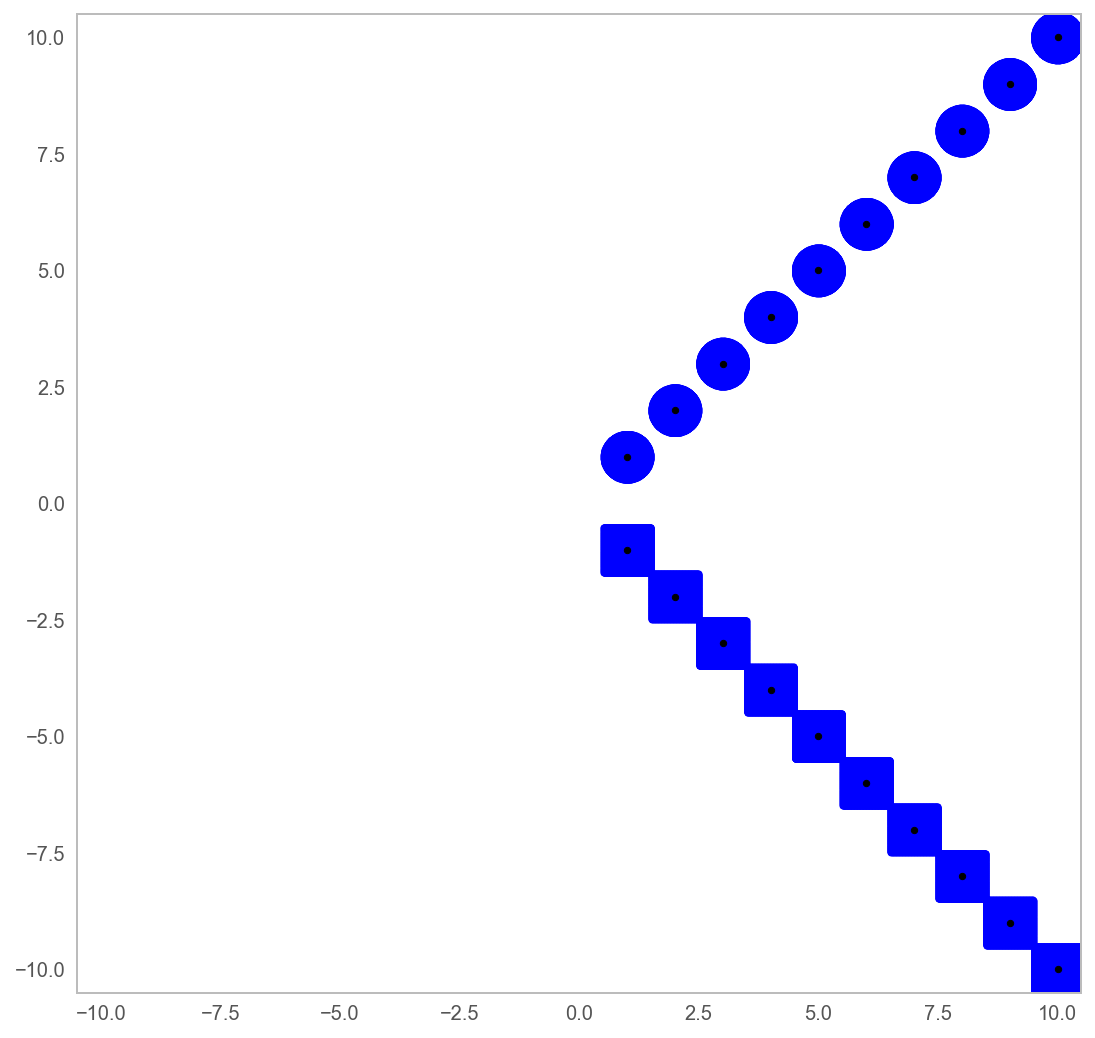

In [7]:
D = geom.disque([0, 0], 0.5)
P = geom.polygone([[-0.5, -0.5], [0.5, -0.5], [0.5, 0.5], [-0.5, 0.5]])


fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)

for k in range(10):
    D.move([1, 1])
    D.visualize(ax)
    P.move([1, -1])
    P.visualize(ax)

## Une classe abstraite `forme`

Nous créons à présent une classe abstraite (voir la documentation https://docs.python.org/fr/3/library/abc.html) qui servira de classe parente à toutes les classes d'objets géométriques.

> 1. Créez dans un fichier `forme.py` (n'oubliez pas l'importation dans `__init__.py`) une classe `forme` qui hérite de la classe `ABC` du module `abc`. Vous pourrez utiliser le modèle suivant :
```python
from abc import ABC, abstractmethod

class forme(ABC):
    '''Une classe abstraite pour les formes géométriques'''
    def __init__(self, nom="F"):
        self._name = nom
        
    @abstractmethod
    def move(self, v):
        """déplace la forme géométrique selon le vecteur v"""

    @abstractmethod
    def rotate(self, theta):
        """tourne la forme d'un angle theta"""

```
*N.B. : la décorateur `@abstractmethod` indique que cette fonction n'est pas utilisable par la classe abstraite (cela permet simplement d'y mettre la documentation) et qu'il est indispensable que les fonctions soient codées dans les classes filles.*

> 2. Ajoutez de la même façon les fonctions abstraites `box`, `perimetre`, `_is_in` qui devront être codée dans chaque classe fille.
> 3. Ajoutez la fonctions `gravity` (qui doit toujours être décorée par `@property`) qui retourne une valeur approchée du centre de gravité. Pour cela, vous fabriquerez un maillage de la boîte retournée par la fonction `box` et vous calculerez le barycentre de tous les points qui sont à l'intérieur de la forme.
> 4. Ajoutez la fonction `aire` (qui doit toujours être décorée par `@property`) qui retourne une valeur approchée de l'aire de la forme. Pour cela, vous tirerez 10000 points au hasard dans la boîte retournée par `box` et vous évaluerez l'aire comme le rapport `nb de points à l'intérieur` divisé par 10000 multiplié par l'aire de la boîte.
> 5. Ajoutez la fonction `visualize` qui prend en argument un axe `ax` de `matplotlib`. Cette fonction devra faire un maillage de la boite de la forme et placer un marqueur (`scatter`) en tous les points de ce maillage qui sont à l'intérieur de la forme (utilisez la fonction `_is_in`). Pensez à modifier les bornes de `ax` pour que la figure affiche bien toute la figure.
> 6. Modifiez les classes `disque` et `polygone` pour qu'elles héritent de la classe `forme`.

## Une classe pour une forme construite à partir de deux formes

L'objectif est de pouvoir faire la réunion, l'intersection ou la différence entre deux formes géométriques. Nous construisons donc une classe `double` qui est simplement faite à partir de deux formes.

> 1. Ajoutez dans les classes `disque` et `polygone` une fonction memebre `copy` qui retourne une copie de l'objet. Par exemple pour le disque, elle pourra s'écrire ainsi
```python
def copy(self):
    return self.__class__(self._c, self._r, nom="_" + self._name)
```
> 2. Dans un nouveau fichier `operations.py` (n'oubliez pas de l'importer dans votre `__init__.py`), ajoutez une classe `double` qui héritent de la classe `forme`. La fonction `__init__` de cette classe devra prendre en paramètre deux formes et une chaine de caractères, vérifier que les deux paramètres sont bien de la classe `forme` (à l'aide de la commande `isinstance`), et copier les deux paramètres dans les variables `_F1` et `_F2` (attributs de la classe) et la chaine de caractères dans la variable `_name`.
> 3. Ajoutez dans cette classe toutes les fonctions que vous pouvez. En particulier, 
>    - la fonction `move` qui doit simplement déplacer les deux formes ;
>    - la fonction `copy` ;
>    - la fonction `rotate` : attention pour cette fonction, il n'est pas suffisant de tourner chacune des formes par rapport à leur propre centre de gravité... il faudra donc modifier les fonctions des classes `disque` et `polygone`.

## Les classes dérivées de `double`

> 1. Créez une classe `union` qui dérive de la classe `double` et qui correpond à la réunion de deux formes. On note cette opération $A\cup B$.
> 2. Créez une classe `intersection` qui dérive de la classe `double` et qui correpond à l'intersection de deux formes. On note cette opération $A\cap B$.
> 3. Créez une classe `différence` qui dérive de la classe `double` et qui correpond à la différence de deux formes. On note cette opération $A\backslash B$.
> 4. Créez une classe `différence_symetrique` qui dérive de la classe `double` et qui correpond à la différence symétrique de deux formes. On note cette opération $A\Delta B = (A\cup B)\backslash (A\cap B)$.

*Attention : pour chacune de ces classes, vous aurez à coder les fonctions `box` (toujours décorée de `@property`), `_is_in` et `info`.*

## Testons notre classe

Testez votre classe en exécutant les cellules suivantes.

In [3]:
D = geom.disque([0, 0], 1)
D.move([0, 1])

P0 = geom.polygone([[0, 0], [1, 0], [0, 1]])

P1 = geom.polygone([[0, 0], [1, 0], [1, 1], [0, 1]])
P1.move([0, 1])

I = geom.intersection(D, P1)
I.move([2, 0])
U = geom.union(D, P1)
U.rotate(-0.25*np.pi)
U.move([4, 0])

list_forms = [D, P0, P1, I, U]

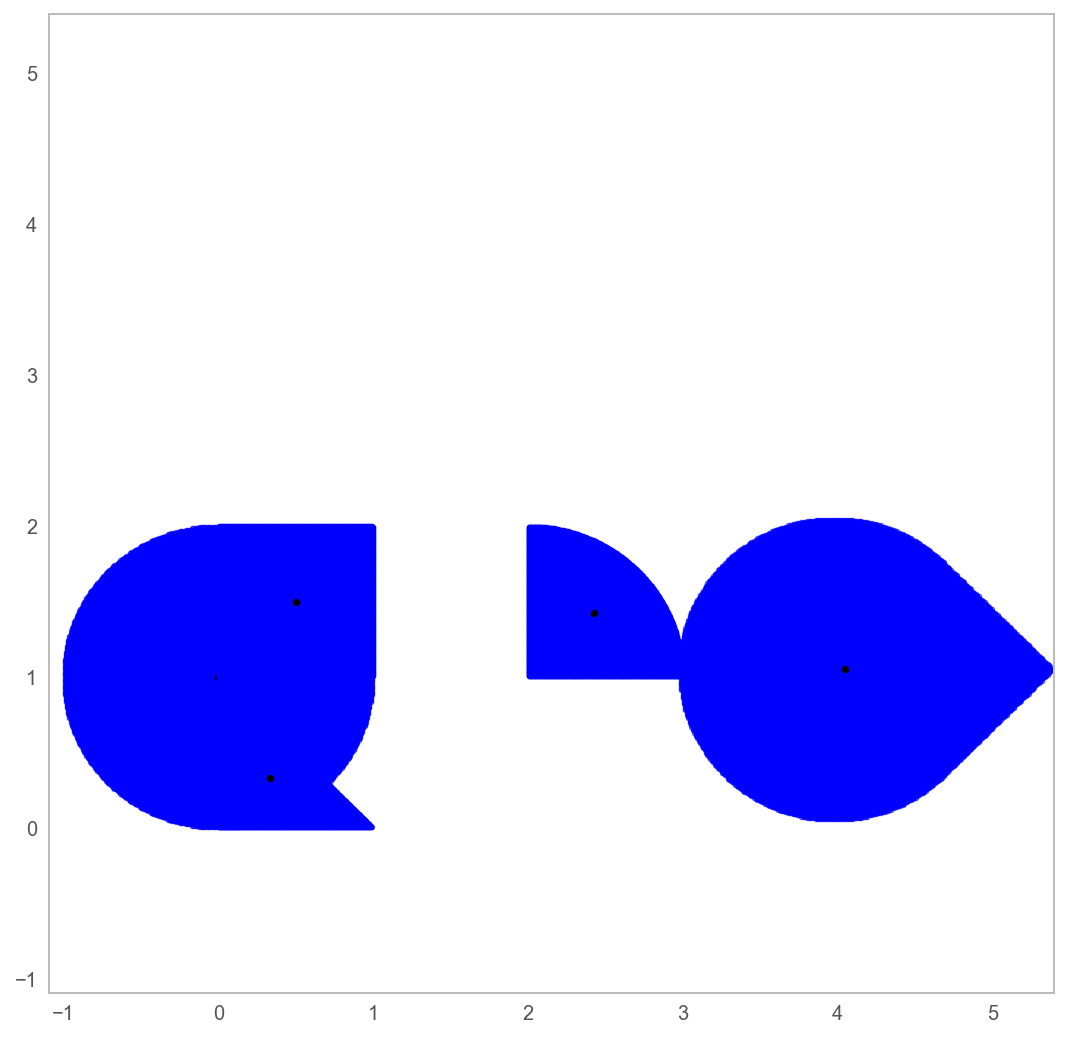

In [4]:
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)

for forme in list_forms:
    forme.visualize(ax)

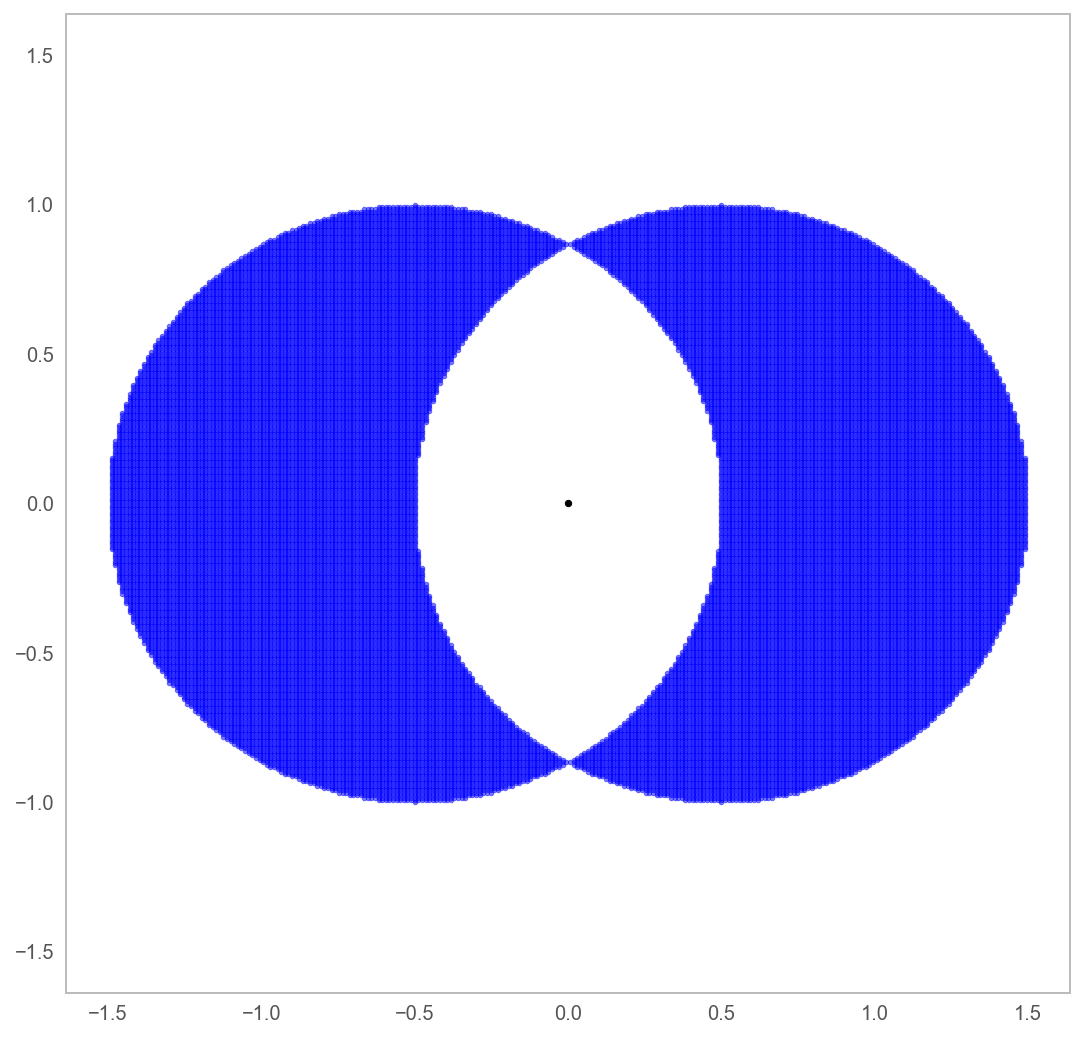

In [5]:
D0 = geom.disque([0, 0], 1)

D1 = D0.copy()
D1.move([.5, 0])

D2 = D0.copy()
D2.move([-.5, 0])

DD = geom.difference_symetrique(D1, D2)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
DD.visualize(ax)

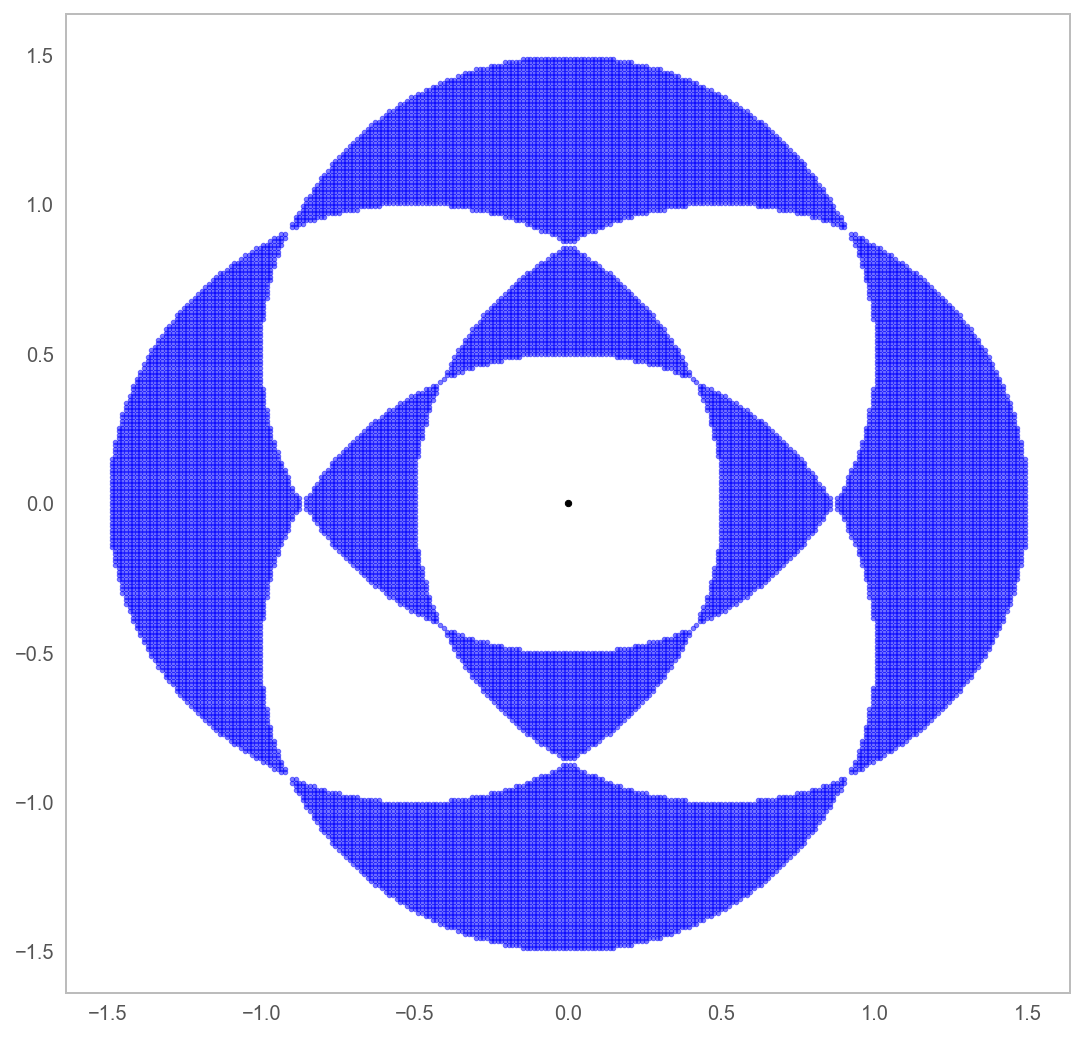

In [6]:
D0 = geom.disque([0, 0], 1)

D1 = D0.copy()
D1.move([.5, 0])

D2 = D0.copy()
D2.move([-.5, 0])

D3 = D0.copy()
D3.move([0, -.5])

D4 = D0.copy()
D4.move([0, .5])

DD = geom.difference_symetrique(
    geom.difference_symetrique(D1, D2),
    geom.difference_symetrique(D3, D4)
)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
DD.visualize(ax)

fig.savefig("difference_symetrique.png")